In [1]:
# Clustering
# Introduction to single-cell RNA-seq workshop
# Author: Harvard Chan Bioinformatics Core
# August 2026
# 改了 util/ 里的 .py 后自动重新加载，不用重启 kernel
%load_ext autoreload
%autoreload 2

# Load libraries
import scanpy as sc
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys

# 改了 util/ 里的 .py 后自动重新加载，不用重启 kernel
%load_ext autoreload
%autoreload 2

sys.path.append("util")
from pca_heatmap import pca_heatmap

# Load data
adata_integrated = sc.read_h5ad("data/adata_integrated.h5ad")

# Set randomness
np.random.seed(1234)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


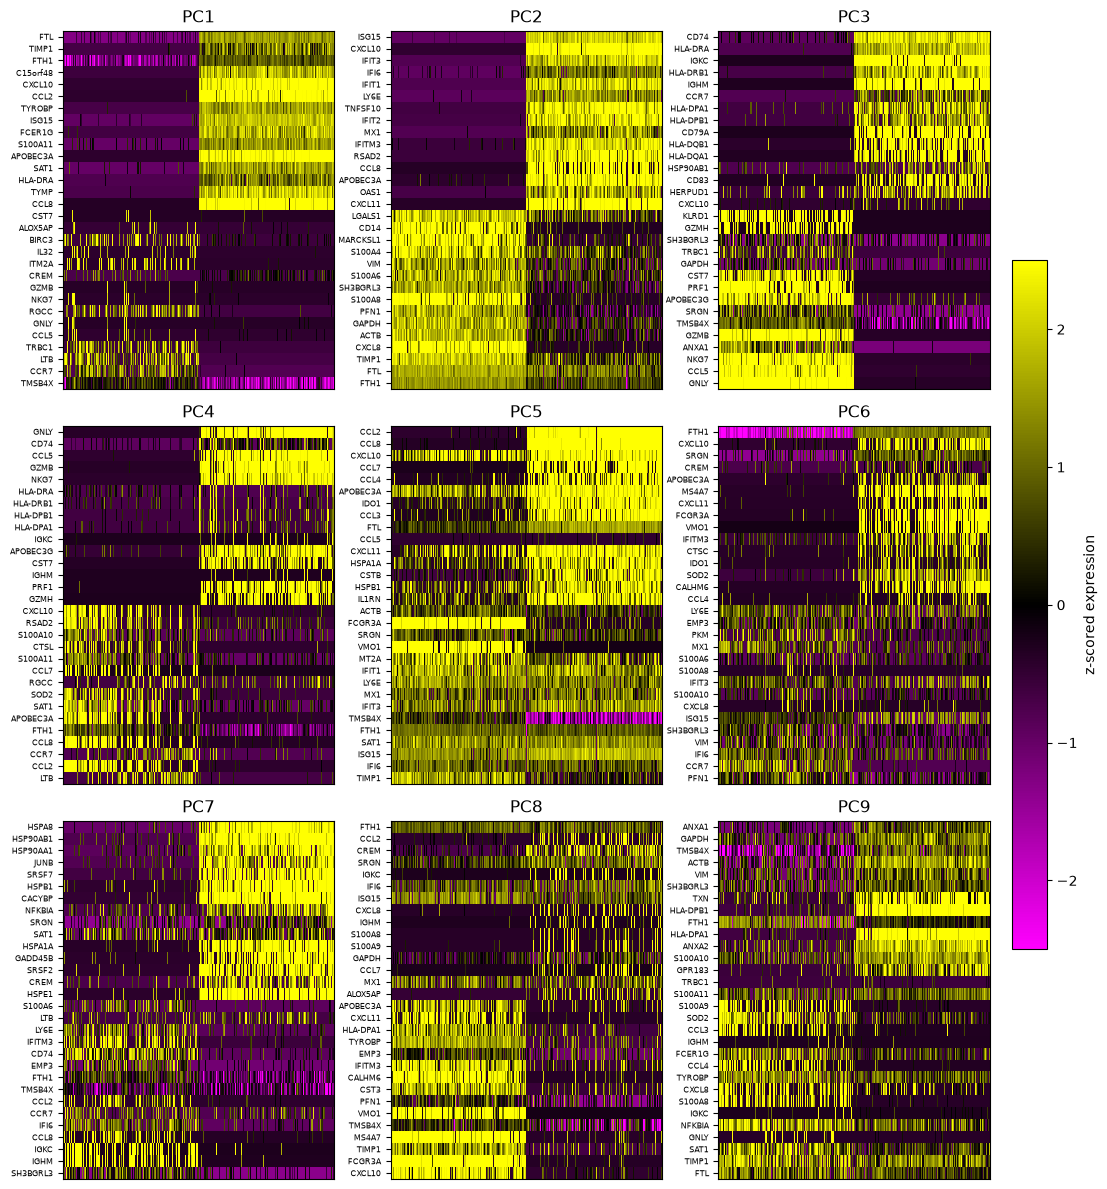

In [2]:
pca_heatmap(adata_integrated) 

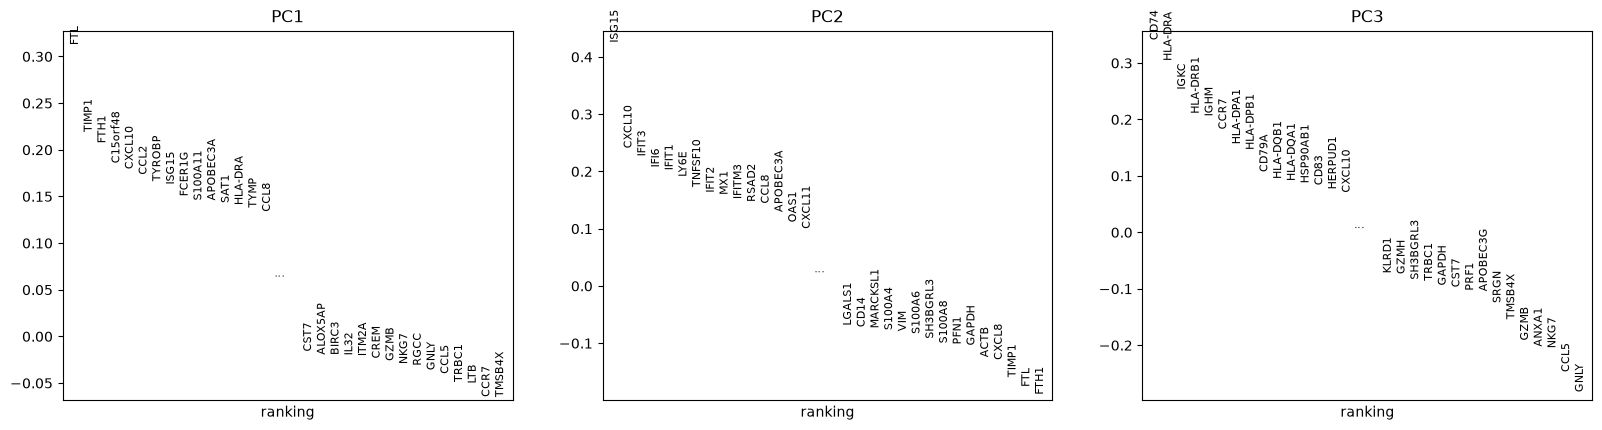

In [3]:
# Print top and bottom ranked genes for first 3 PCs
sc.pl.pca_loadings(adata_integrated,
                   components = "1,2,3")

In [4]:
   pc = 0  # PC1
   order = np.argsort(adata_integrated.varm['PCs'][:, pc])
   genes = adata_integrated.var_names
   print("bottom:", genes[order[:10]].tolist())
   print("top:", genes[order[-10:]].tolist())

bottom: ['TMSB4X', 'CCR7', 'LTB', 'TRBC1', 'CCL5', 'GNLY', 'RGCC', 'NKG7', 'GZMB', 'CREM']
top: ['S100A11', 'FCER1G', 'ISG15', 'TYROBP', 'CCL2', 'CXCL10', 'C15orf48', 'FTH1', 'TIMP1', 'FTL']


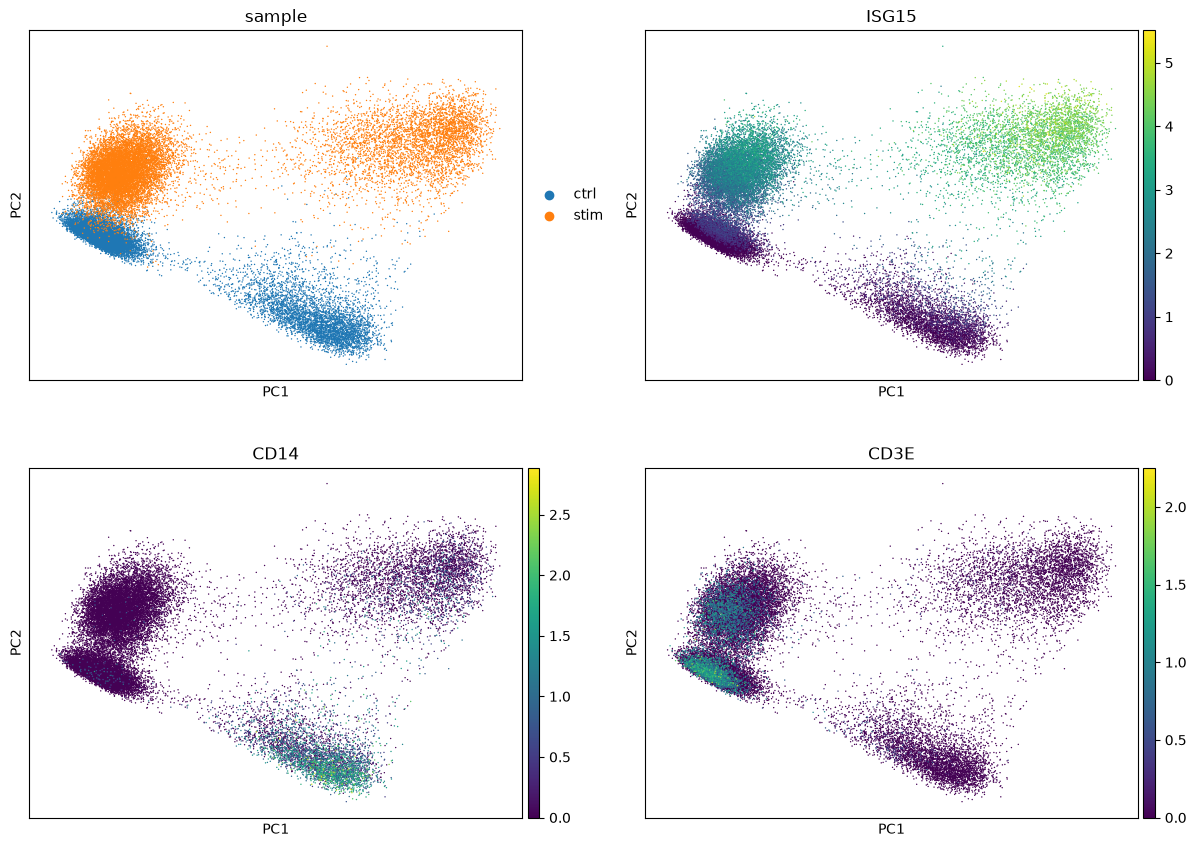

In [5]:
# PC1/PC2 colored by condition, IFN response, and lineage markers
# (no cell_type column yet, so CD14 = myeloid, CD3E = T cells as stand-ins)
sc.pl.pca(adata_integrated,
          color=['sample', 'ISG15', 'CD14', 'CD3E'],
          components=['1,2'],
          ncols=2)

### 结果解读：PCA（整合前，`X_pca`）

**PC1：细胞谱系轴**，和前面看基因列表时的判断一致
- 左边的两团 CD3E 高，是淋巴细胞。
- 右边的两团 CD14 高，是单核和髓系细胞。

**PC2：几乎就是刺激轴**
- 每个谱系都被 PC2 干净地分成上下两团：上面是 stim，下面是 ctrl。
- ISG15 的颜色和 stim 完全重合，而且右上角的髓系 stim 细胞最亮，说明单核细胞对 IFN 的反应最强。

所以条件效应非常强，强到成了第二大变异来源。这个数据里的条件效应就是这么大。

**一个容易误判的地方**

看 CD14 那张图：右上角的 stim 髓系细胞 CD14 几乎是 0，只有 ctrl 的髓系细胞亮。这不代表它们不是单核细胞，因为它们在 PC1 上的位置明明是髓系。原因是 IFN 刺激后单核细胞会**下调 CD14**。后面做细胞类型注释时要注意：只靠 CD14 判断，会把 stim 组的单核细胞漏掉。更稳的是一起看 *LYZ*、*FCER1G*、*TYROBP*、*S100A8/9* 这些 marker。

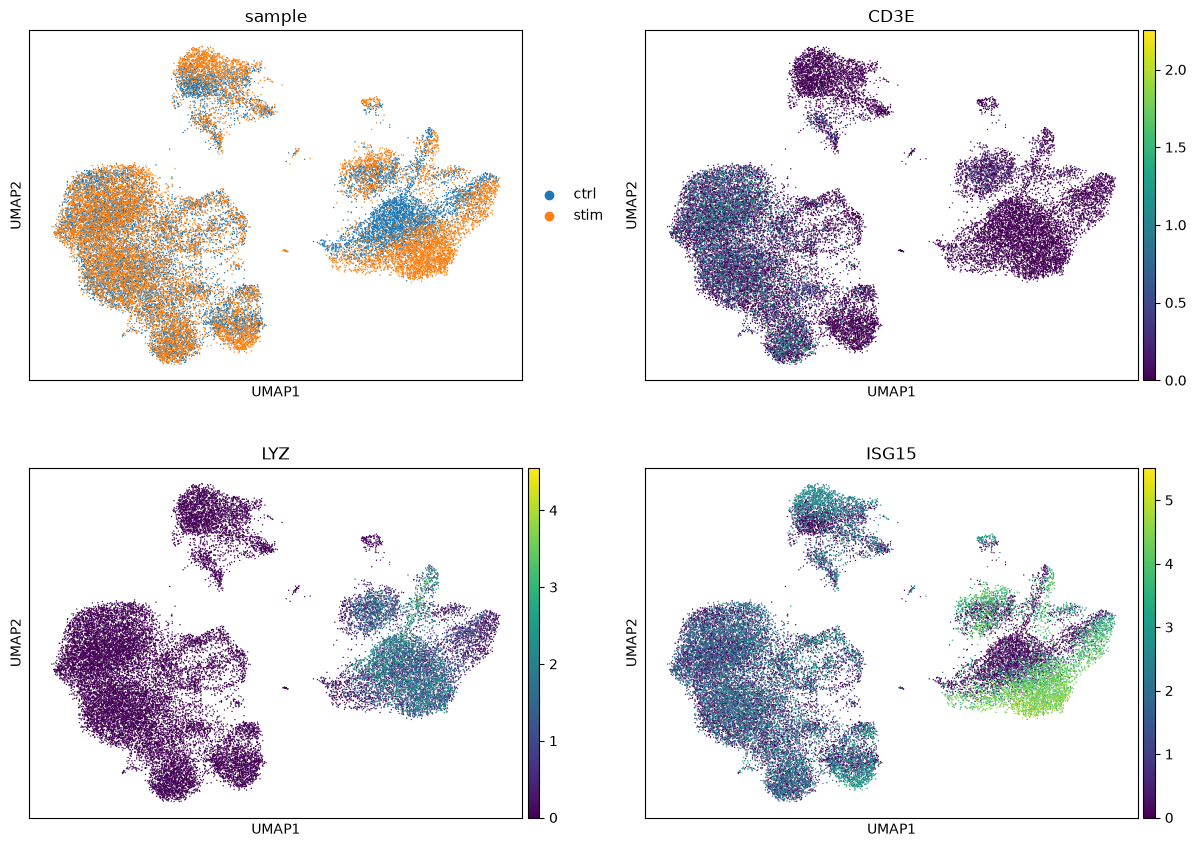

In [6]:
# Check scVI integration: neighbors + UMAP on the integrated latent space
sc.pp.neighbors(adata_integrated, use_rep='X_scvi')
sc.tl.umap(adata_integrated)
sc.pl.umap(adata_integrated,
           color=['sample', 'CD3E', 'LYZ', 'ISG15'],
           ncols=2)

### 结果解读：scVI 整合后的 UMAP（`X_scvi`）

**结论：整合总体成功。** 淋巴细胞对齐得很好，髓系细胞还保留了一部分条件差异，这是合理的。

**左边和上方的淋巴细胞：ctrl 和 stim 混得很均匀**
- 左边的大团是 T 细胞（CD3E 亮），下面的小团 CD3E 偏暗，可能是 NK。上方单独的一团 CD3E 和 LYZ 都不亮，大概率是 B 细胞。
- 这几团里蓝色和橙色交织在一起，说明 scVI 把两个条件的同类细胞对齐了。对比整合前，PCA 上它们是按 PC2 完全分开的。

**右边的髓系细胞（LYZ 亮）：同在一个岛上，但内部还是按条件分层**
- ctrl 集中在中间那条带，stim 集中在下方和外缘。
- ISG15 最亮的正好是 stim 那一片。

**髓系没有完全混开，算不算问题？**

我认为**不算**。前面已经看到，单核细胞对 IFN-β 的反应是全数据里最强的生物学信号：几百个基因大幅变化，连 CD14 都被下调了。scVI 的做法是让所有单核细胞落在同一个岛上（细胞身份对齐了），同时保留刺激带来的状态差异。这正是整合想要的平衡。如果强行把这部分也混平，就是**过度校正**，后面做 ctrl vs stim 的差异分析时，真正的信号也会被抹掉。

**后面聚类时要注意**
- 髓系很可能被分成 “ctrl 单核” 和 “stim 单核” 两个 cluster。注释时把它们归为**同一种细胞类型、不同状态**就行，不要当成两种细胞。
- 单核细胞不要只靠 CD14 判断（stim 组的被下调了），LYZ 这张图就比 CD14 更可靠。
- 要比较条件，建议先注释细胞类型，再在每种细胞类型内部比较 ctrl 和 stim（比如做 pseudobulk DE），而不是在 cluster 层面比较。

下一步可以直接用 `sc.tl.leiden` 试几个 resolution 做聚类。

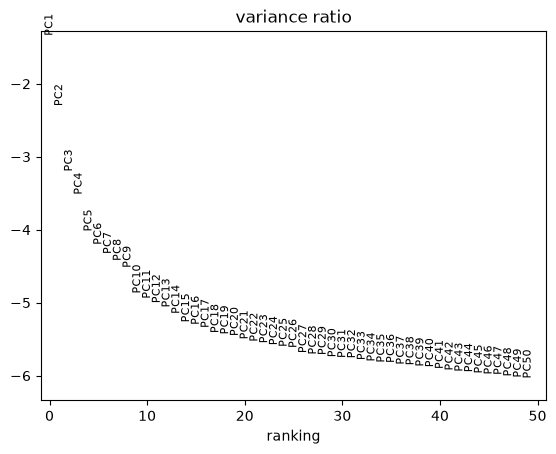

In [7]:
# Elbow plot visualization
sc.pl.pca_variance_ratio(adata_integrated, 
                         n_pcs = 50, log = True)

In [8]:
# Calculate neighbors
sc.pp.neighbors(adata_integrated, 
                use_rep = "X_scvi", 
                key_added = "scvi",
                random_state = 1234)

In [9]:
# Calculation of UMAP
sc.tl.umap(adata_integrated,
           neighbors_key = "scvi", 
           key_added = "umap_scvi",
           random_state = 1234)

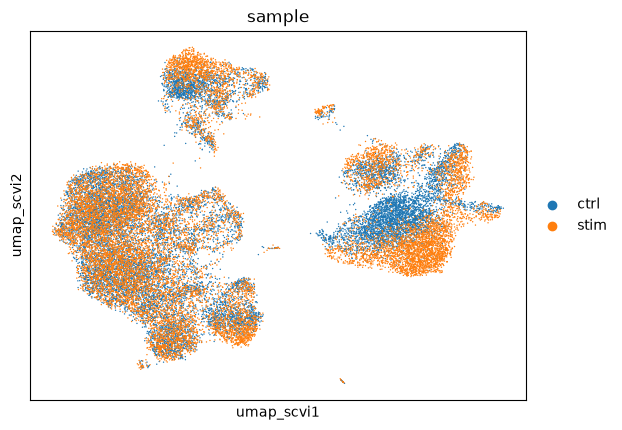

In [10]:
# UMAP colored by sample
sc.pl.embedding(adata_integrated, 
                color = "sample", 
                basis = "umap_scvi")

In [11]:
adata_integrated

AnnData object with n_obs × n_vars = 29629 × 14167
    obs: 'n_genes', 'sample', 'n_genes_by_counts', 'total_counts', 'cells', 'log10GenesPerUMI', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'mito_ratio', 'S_score', 'G2M_score', 'phase', 'mitoFr', '_scvi_batch', '_scvi_labels'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mito', 'log1p_mean_counts', 'log1p_total_counts', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'hvg', 'log1p', 'mitoFr_colors', 'pca', 'phase_colors', 'sample_colors', 'neighbors', 'umap', 'scvi', 'umap_scvi'
    obsm: 'X_pca', 'X_scvi', '_scvi_extra_categorical_covs', 'X_umap', 'umap_scvi'
    varm: 'PCs'
    obsp: 

In [12]:
# List of resolution values to test
resolutions = [0.4, 0.6, 0.8, 1.0, 1.4]

for res in resolutions:
    sc.tl.leiden(adata_integrated,
                 flavor = "igraph", 
                 n_iterations = 2, 
                 neighbors_key = "scvi", 
                 resolution = res,
                 key_added = f"leiden_{res}")

In [13]:
# View updated metadata
adata_integrated.obs.head()

,n_genes,sample,n_genes_by_counts,total_counts,cells,log10GenesPerUMI,log1p_n_genes_by_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,...,G2M_score,phase,mitoFr,_scvi_batch,_scvi_labels,leiden_0.4,leiden_0.6,leiden_0.8,leiden_1.0,leiden_1.4
AAACATACAATGCC-1_ctrl,874,ctrl,874,2344.0,AAACATACAATGCC-1_ctrl,0.872863,6.774224,7.760041,47.568259,59.129693,...,0.016737,G2M,Medium,0,0,0,0,0,0,0
AAACATACATTTCC-1_ctrl,896,ctrl,896,3125.0,AAACATACATTTCC-1_ctrl,0.844760,6.799056,8.047509,51.904000,63.456000,...,0.003142,S,Medium,0,0,4,6,5,8,6
AAACATACCAGAAA-1_ctrl,725,ctrl,725,2578.0,AAACATACCAGAAA-1_ctrl,0.838493,6.587550,7.855157,61.947246,69.550039,...,-0.032831,G1,Medium,0,0,4,6,5,8,7
AAACATACCAGCTA-1_ctrl,979,ctrl,979,3261.0,AAACATACCAGCTA-1_ctrl,0.851262,6.887553,8.090096,52.836553,62.557498,...,-0.001563,G1,Low,0,0,5,7,6,10,9
AAACATACCATGCA-1_ctrl,362,ctrl,362,746.0,AAACATACCATGCA-1_ctrl,0.890686,5.894403,6.616065,53.887399,64.879357,...,-0.032109,S,Medium high,0,0,7,3,2,3,3


In [14]:
# Number of cells per cluster
adata_integrated.obs["leiden_0.8"].value_counts()

leiden_0.8
0     5957
5     5479
1     5144
7     2915
4     2030
2     1996
3     1823
6     1579
12    1190
11     410
9      406
10     375
13     169
8      128
14      28
Name: count, dtype: int64

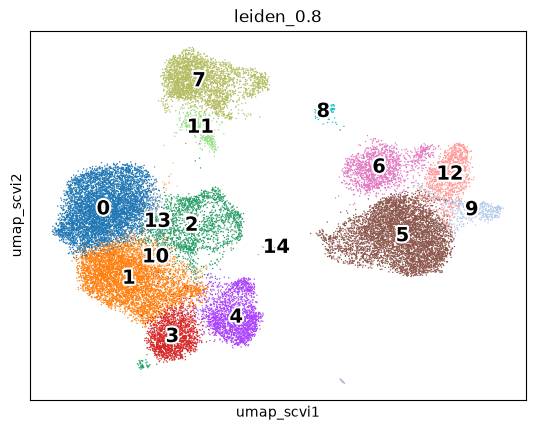

In [15]:
# Plot the UMAP
sc.pl.embedding(adata_integrated, 
                color = "leiden_0.8", 
                basis = "umap_scvi",
                legend_loc = "on data",
                legend_fontsize = 14,
                legend_fontoutline = 3)

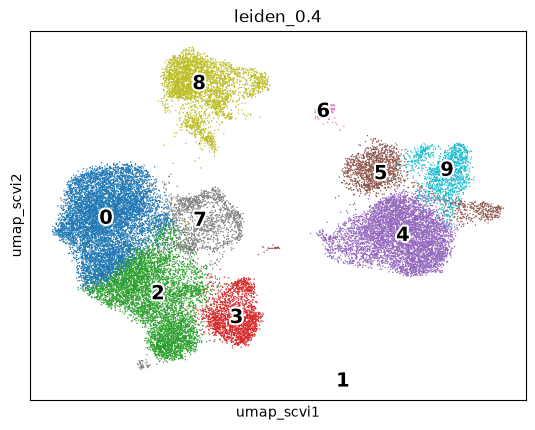

In [16]:
# Plot the UMAP
sc.pl.embedding(adata_integrated, 
                color = "leiden_0.4", 
                basis = "umap_scvi",
                legend_loc = "on data",
                legend_fontsize = 14,
                legend_fontoutline = 3)